
# STRATUM — Wafer Uniformity and Multi-Parameter Quality Analysis

## Phase 2 — Step 2.5

### Objective

Investigate wafer-level thickness uniformity, electrical-property
variation, spatially indexed measurement profiles, quality-label
relationships, and equipment-specific quality outcomes.

### Research Questions

1. How much do the 17 thickness measurements vary within each wafer?
2. How much do sheet resistance and derived resistivity vary?
3. Do measurement profiles show systematic variation across indices?
4. Which property-quality failures contribute to overall failures?
5. Can a wafer pass thickness quality and still fail overall quality?
6. Do quality-label distributions differ across equipment?
7. Are within-wafer variation metrics related to quality outcomes?

### Methodological Notes

- The original dataset remains unchanged.
- All measurements are historical post-process SPC results.
- Quality labels are supplied by the dataset publishers.
- Industrial acceptance limits are not publicly disclosed.
- Uniformity indicators are descriptive, not official specifications.
- Measurement indices follow a spiral sequence, but exact wafer
  coordinates are unavailable.
- This notebook does not train or evaluate ML models.

In [1]:

# STEP 2.5.2 - Load the Infineon AlCu dataset

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

filename = "apc_spc_AlCu_inputs_outputs.csv"

current_dir = Path.cwd()

csv_path = current_dir / "data" / "raw" / filename

if not csv_path.exists():
    csv_path = current_dir.parent / "data" / "raw" / filename

if not csv_path.exists():
    raise FileNotFoundError(
        f"Dataset not found. Working directory: {current_dir}"
    )

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False
)

# Work on a separate in-memory copy
analysis_df = df.copy()

print("STRATUM - Wafer Uniformity and Quality Analysis")
print("Dataset shape:", analysis_df.shape)
print("Dataset loaded successfully!")

STRATUM - Wafer Uniformity and Quality Analysis
Dataset shape: (5208, 178)
Dataset loaded successfully!


## 1. Measurement Column Identification

Identify the 17 indexed measurements corresponding to
film thickness, sheet resistance, and derived resistivity.

The thickness and resistance measurements occur at nearby
but not identical physical locations.

In [3]:

# STEP 2.5.3 - Identify measurement columns

thickness_cols = [
    f"RAW_VALUE_t_{i}" for i in range(1, 18)
]

resistance_cols = [
    f"RAW_VALUE_r_{i}" for i in range(1, 18)
]

resistivity_cols = [
    f"RAW_VALUE_{i}" for i in range(1, 18)
]

measurement_groups = {
    "Thickness": thickness_cols,
    "Sheet Resistance": resistance_cols,
    "Derived Resistivity": resistivity_cols
}

for group, cols in measurement_groups.items():
    missing = [col for col in cols if col not in analysis_df.columns]

    if missing:
        raise ValueError(f"Missing {group} columns: {missing}")

    print(f"{group}: {len(cols)} measurement columns")

print("\nTotal point measurements:",
      sum(len(cols) for cols in measurement_groups.values()))

Thickness: 17 measurement columns
Sheet Resistance: 17 measurement columns
Derived Resistivity: 17 measurement columns

Total point measurements: 51


## 2. Within-Wafer Measurement Variation

Calculate range, standard deviation, and coefficient of
variation (CV) for all three material properties.

These measures describe variation among recorded points.
They are not official Infineon acceptance criteria.

Population standard deviation (ddof=0) is used across
each wafer's 17 available measurements.

In [4]:

# STEP 2.5.4 - Within-wafer variation

def add_variation_metrics(data, columns, prefix):
    values = data[columns]

    data[f"{prefix}_mean_17pt"] = values.mean(axis=1)

    data[f"{prefix}_range"] = (
        values.max(axis=1) - values.min(axis=1)
    )

    data[f"{prefix}_std"] = values.std(
        axis=1,
        ddof=0
    )

    mean_values = data[f"{prefix}_mean_17pt"]

    data[f"{prefix}_cv_pct"] = np.where(
        mean_values != 0,
        data[f"{prefix}_std"] / mean_values.abs() * 100,
        np.nan
    )

for name, columns in [
    ("thickness", thickness_cols),
    ("resistance", resistance_cols),
    ("resistivity", resistivity_cols)
]:
    add_variation_metrics(
        analysis_df,
        columns,
        name
    )

summary_cols = [
    "thickness_cv_pct",
    "resistance_cv_pct",
    "resistivity_cv_pct"
]

print("Within-wafer variation summary:")

display(
    analysis_df[summary_cols]
    .describe()
    .round(4)
)

print("\nFirst five wafer records:")

display(
    analysis_df[
        ["wafer_id"] + summary_cols
    ].head().round(4)
)

Within-wafer variation summary:


,thickness_cv_pct,resistance_cv_pct,resistivity_cv_pct
count,5208.0000,5208.0000,5208.0000
mean,2.4410,2.6694,0.3807
std,0.4950,0.5158,0.1561
min,1.4014,0.6698,0.0915
25%,2.0959,2.3109,0.2550
50%,2.3699,2.6453,0.3479
75%,2.7145,2.9662,0.4910
max,4.2903,4.6503,2.1177



First five wafer records:


,wafer_id,thickness_cv_pct,resistance_cv_pct,resistivity_cv_pct
0,V612511104,2.1945,2.4800,0.5711
1,V612511105,2.5925,2.7515,0.4803
2,V612511106,2.7751,3.1495,0.5551
3,V612511116,2.3964,2.5134,0.3960
4,V612515010,2.1915,2.4656,0.5918


## 3. Distribution of Within-Wafer Variation

Visualise the coefficient of variation for thickness,
sheet resistance, and derived resistivity.

Identify the typical range of variation and
investigate unusually high values.

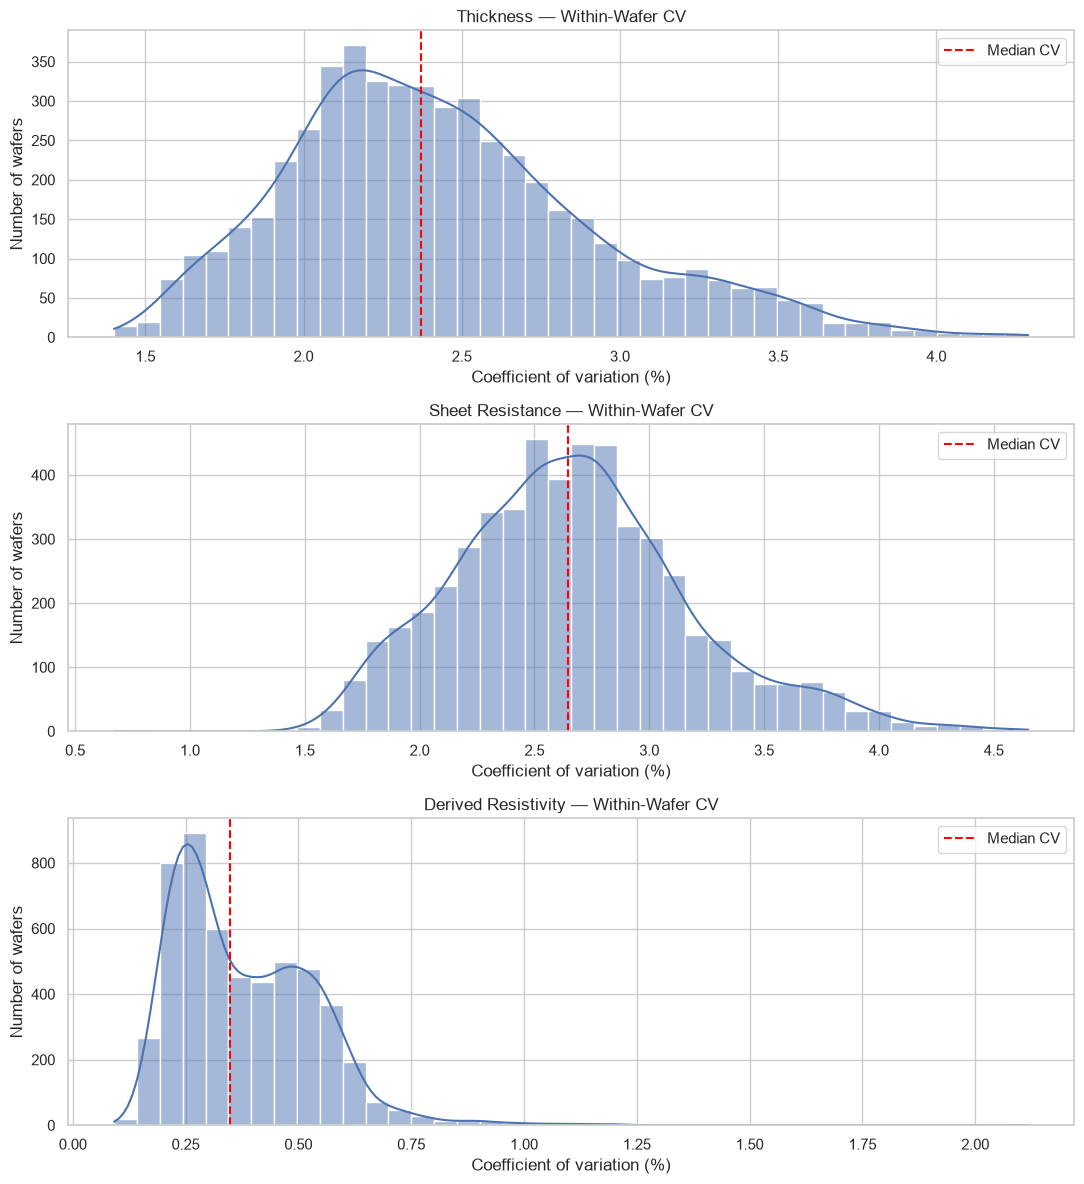

In [5]:

# STEP 2.5.5 - Uniformity distributions

cv_columns = {
    "Thickness": "thickness_cv_pct",
    "Sheet Resistance": "resistance_cv_pct",
    "Derived Resistivity": "resistivity_cv_pct"
}

fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 12)
)

for ax, (name, col) in zip(axes, cv_columns.items()):

    sns.histplot(
        data=analysis_df,
        x=col,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(
        analysis_df[col].median(),
        color="red",
        linestyle="--",
        label="Median CV"
    )

    ax.set_title(f"{name} — Within-Wafer CV")
    ax.set_xlabel("Coefficient of variation (%)")
    ax.set_ylabel("Number of wafers")
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Dataset-Wide Measurement Profiles

Analyse average measurements across the 17 indexed positions.

Point 1 corresponds to the central measurement location,
and Point 17 is the outermost indexed location.

Intermediate positions follow a spiral trajectory.

Exact spatial coordinates are not provided, so these plots
are indexed profiles rather than physical wafer maps.

The thickness and sheet-resistance locations are nearby
but not identical.

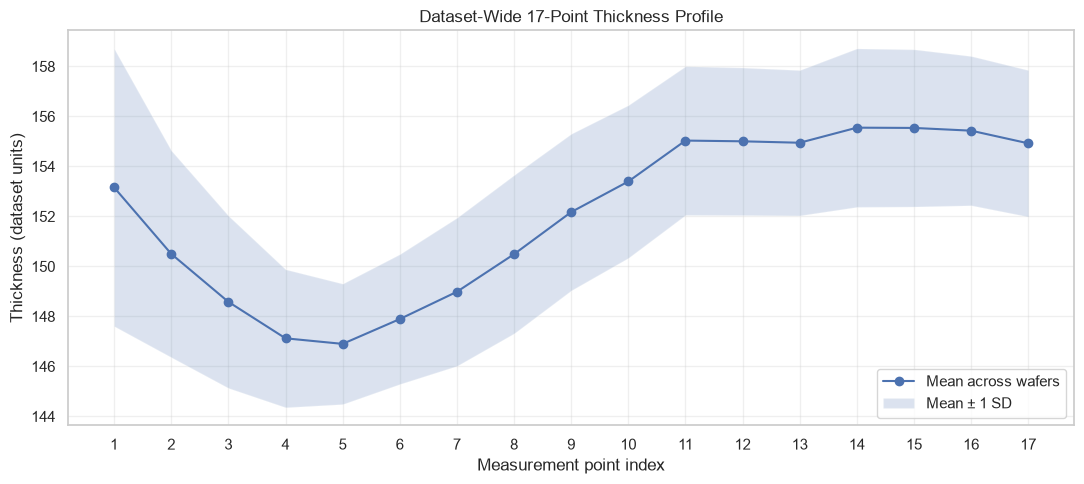

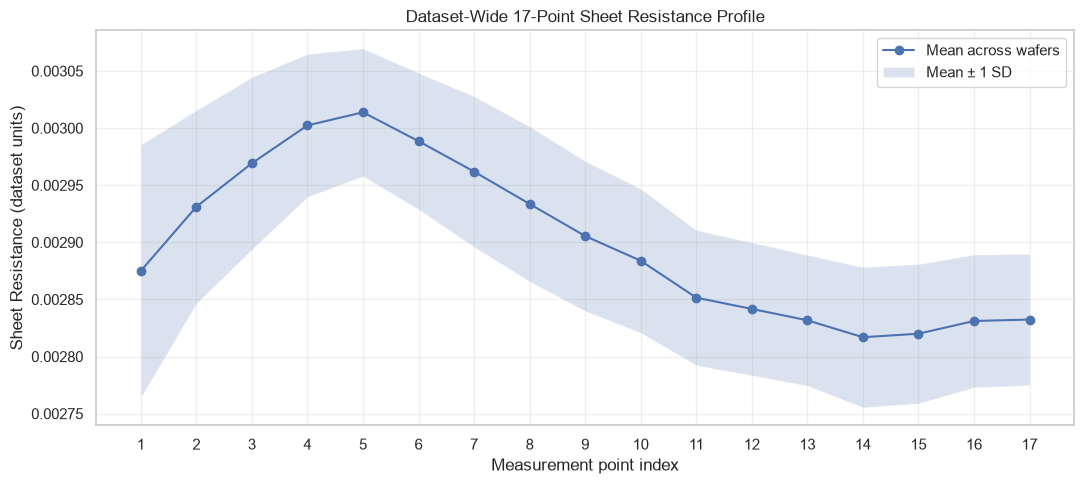

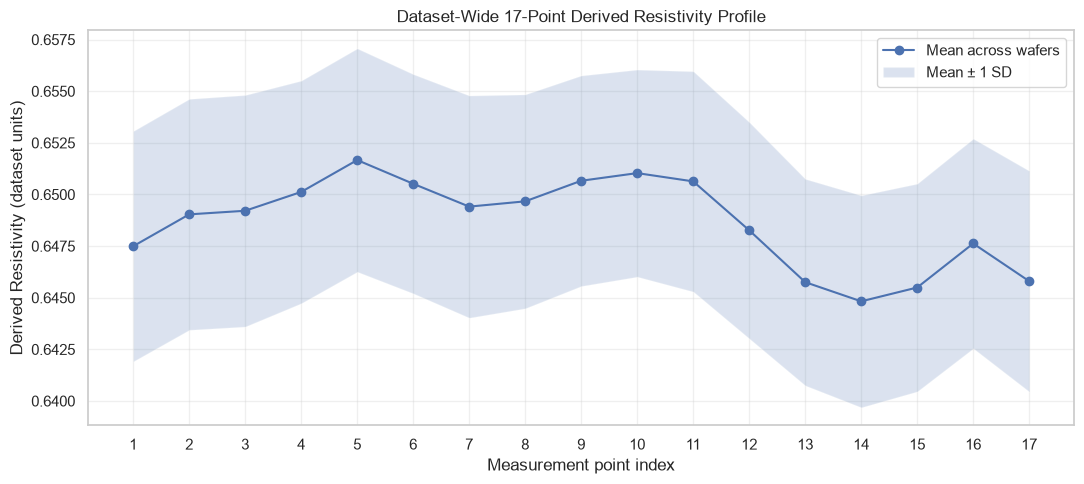

In [6]:

# STEP 2.5.6 - Average 17-point profiles

points = np.arange(1, 18)

profile_groups = {
    "Thickness": thickness_cols,
    "Sheet Resistance": resistance_cols,
    "Derived Resistivity": resistivity_cols
}

for property_name, columns in profile_groups.items():

    values = analysis_df[columns]

    point_means = values.mean(axis=0).to_numpy(dtype=float)
    point_stds = values.std(axis=0).to_numpy(dtype=float)

    plt.figure(figsize=(11, 5))

    plt.plot(
        points,
        point_means,
        marker="o",
        label="Mean across wafers"
    )

    plt.fill_between(
        points,
        point_means - point_stds,
        point_means + point_stds,
        alpha=0.2,
        label="Mean ± 1 SD"
    )

    plt.title(
        f"Dataset-Wide 17-Point {property_name} Profile"
    )

    plt.xlabel("Measurement point index")
    plt.ylabel(f"{property_name} (dataset units)")
    plt.xticks(points)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 5. Multi-Parameter Quality Failure Analysis

Investigate combinations of thickness, sheet resistance,
and resistivity quality classifications.

The quality indicators originate from the public dataset.

The analysis does not introduce new industrial thresholds.

In [7]:

# STEP 2.5.7 - Quality label combinations

quality_cols = [
    "quality_thickness",
    "quality_resistance",
    "quality_resistivity"
]

# Standardise labels in the analysis copy
for col in quality_cols:
    analysis_df[col] = (
        analysis_df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# Validate allowed labels
for col in quality_cols:
    assert analysis_df[col].isin(["good", "bad"]).all(), (
        f"Invalid quality labels in {col}"
    )

analysis_df["thickness_bad"] = (
    analysis_df["quality_thickness"] == "bad"
)

analysis_df["resistance_bad"] = (
    analysis_df["quality_resistance"] == "bad"
)

analysis_df["resistivity_bad"] = (
    analysis_df["quality_resistivity"] == "bad"
)

# Create a readable failure combination
def describe_failures(row):
    failed = []

    if row["thickness_bad"]:
        failed.append("Thickness")

    if row["resistance_bad"]:
        failed.append("Resistance")

    if row["resistivity_bad"]:
        failed.append("Resistivity")

    return " + ".join(failed) if failed else "None"

analysis_df["failure_combination"] = (
    analysis_df.apply(describe_failures, axis=1)
)

failure_counts = (
    analysis_df["failure_combination"]
    .value_counts()
)

display(
    failure_counts.to_frame("Wafer Count")
)

# Verify consistency with overall quality
derived_overall = analysis_df[
    ["thickness_bad", "resistance_bad", "resistivity_bad"]
].any(axis=1).astype(int)

assert (
    derived_overall == analysis_df["quality_overall"]
).all()

print("Overall quality labels verified.")

,Wafer Count
failure_combination,
None,4873
Resistivity,268
Resistance,29
Resistance + Resistivity,26
Thickness + Resistance,7
Thickness,4
Thickness + Resistivity,1


Overall quality labels verified.


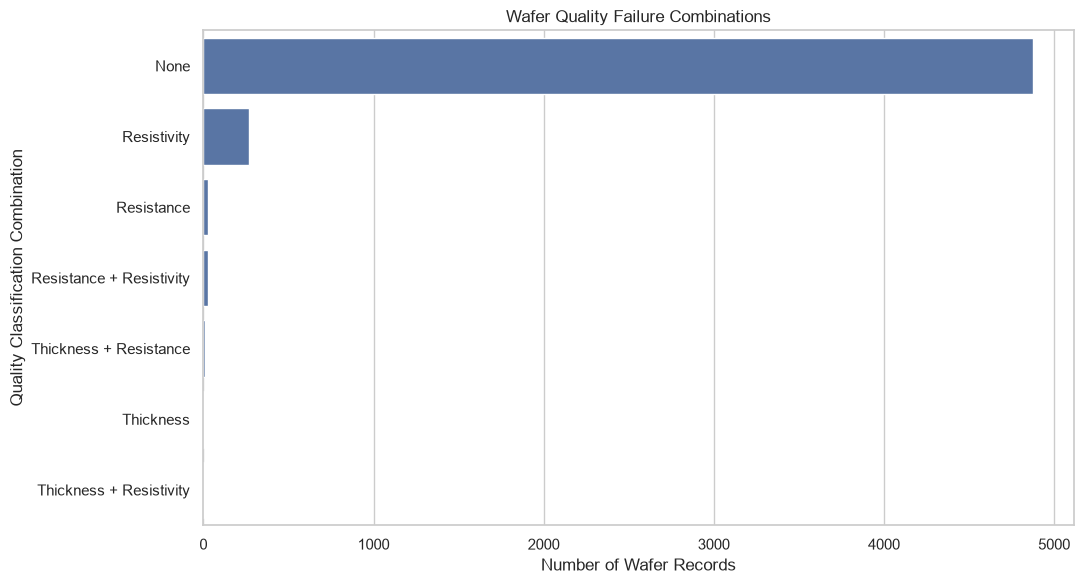

In [8]:

# Plot quality failure combinations

plt.figure(figsize=(11, 6))

sns.barplot(
    x=failure_counts.values,
    y=failure_counts.index
)

plt.title("Wafer Quality Failure Combinations")
plt.xlabel("Number of Wafer Records")
plt.ylabel("Quality Classification Combination")

plt.tight_layout()
plt.show()


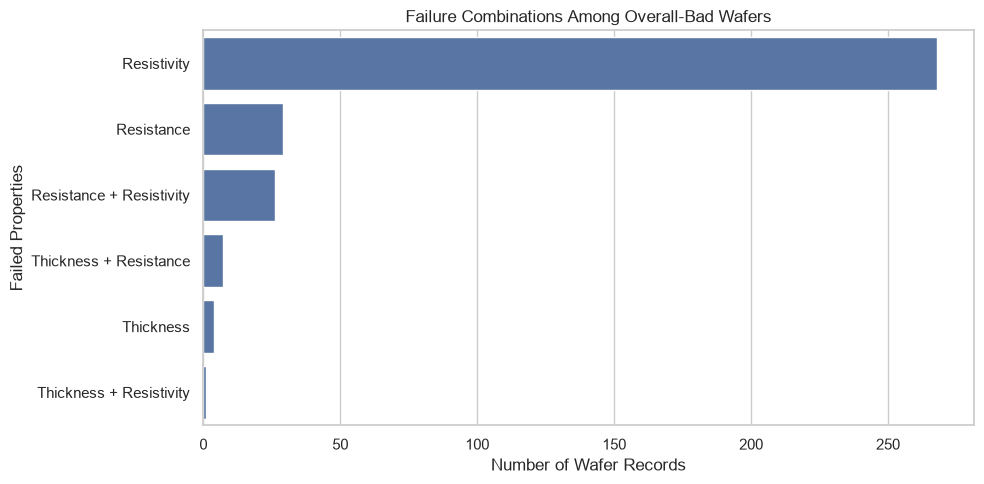

In [9]:

# Failure combinations among overall-bad wafers only

bad_failure_counts = (
    analysis_df.loc[
        analysis_df["quality_overall"] == 1,
        "failure_combination"
    ]
    .value_counts()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=bad_failure_counts.values,
    y=bad_failure_counts.index
)

plt.title("Failure Combinations Among Overall-Bad Wafers")
plt.xlabel("Number of Wafer Records")
plt.ylabel("Failed Properties")

plt.tight_layout()
plt.show()

## 6. Uniformity and Quality Relationships

Compare within-wafer variation metrics between good
and bad property-quality classifications.

A statistical association does not establish causation.

Quality labels depend on undisclosed acceptance limits
applied to the 17 measurements, so this analysis is
descriptive rather than independent validation.

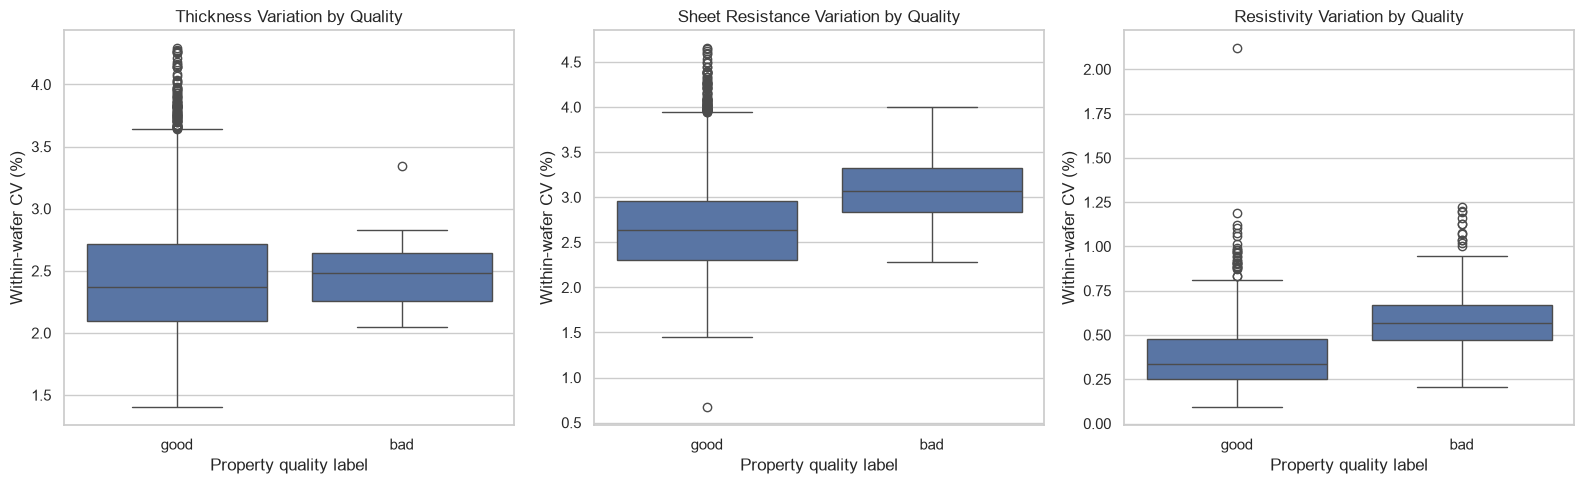

In [10]:

# STEP 2.5.8 - Compare CV with quality classifications

comparisons = [
    ("Thickness", "thickness_cv_pct", "quality_thickness"),
    ("Sheet Resistance", "resistance_cv_pct", "quality_resistance"),
    ("Resistivity", "resistivity_cv_pct", "quality_resistivity")
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, (name, cv_col, quality_col) in zip(
    axes, comparisons
):
    sns.boxplot(
        data=analysis_df,
        x=quality_col,
        y=cv_col,
        order=["good", "bad"],
        ax=ax
    )

    ax.set_title(f"{name} Variation by Quality")
    ax.set_xlabel("Property quality label")
    ax.set_ylabel("Within-wafer CV (%)")

plt.tight_layout()
plt.show()

In [11]:

# Numerical comparison of variation and quality

for name, cv_col, quality_col in comparisons:

    print(f"\n{name}:")

    summary = (
        analysis_df
        .groupby(quality_col)[cv_col]
        .agg(["count", "mean", "median", "std"])
    )

    display(summary.round(4))


Thickness:


,count,mean,median,std
quality_thickness,,,,
bad,12,2.5143,2.4814,0.3450
good,5196,2.4408,2.3696,0.4953



Sheet Resistance:


,count,mean,median,std
quality_resistance,,,,
bad,62,3.0975,3.0668,0.3454
good,5146,2.6642,2.6384,0.5153



Resistivity:


,count,mean,median,std
quality_resistivity,,,,
bad,295,0.5853,0.5700,0.1829
good,4913,0.3684,0.3343,0.1455


## 7. Equipment-Level Quality Monitoring

Calculate the percentage of wafer records with
overall-bad quality labels for each equipment group.

This analysis is intended to compare recorded outcomes,
not identify faulty equipment or prove root causes.

Equipment sample sizes must be considered.

In [12]:

# STEP 2.5.9 - Equipment-level quality summary

equipment_quality = (
    analysis_df
    .groupby("equipment")
    .agg(
        wafer_count=("wafer_id", "count"),
        overall_bad_count=("quality_overall", "sum"),
        thickness_bad_count=("thickness_bad", "sum"),
        resistance_bad_count=("resistance_bad", "sum"),
        resistivity_bad_count=("resistivity_bad", "sum"),
        mean_thickness_cv=("thickness_cv_pct", "mean"),
        mean_resistance_cv=("resistance_cv_pct", "mean")
    )
)

equipment_quality["overall_bad_pct"] = (
    equipment_quality["overall_bad_count"]
    / equipment_quality["wafer_count"]
    * 100
)

equipment_quality = equipment_quality.sort_values(
    "overall_bad_pct",
    ascending=False
)

display(equipment_quality.round(3))

,wafer_count,overall_bad_count,thickness_bad_count,resistance_bad_count,resistivity_bad_count,mean_thickness_cv,mean_resistance_cv,overall_bad_pct
equipment,,,,,,,,
equipment_15,400,42,0,5,39,3.281,3.585,10.500
equipment_1,423,39,1,6,33,2.319,2.536,9.220
equipment_8,382,34,2,8,32,2.527,2.796,8.901
equipment_13,431,38,0,0,38,2.141,2.418,8.817
equipment_9,412,35,0,0,35,2.135,2.335,8.495
equipment_14,440,30,1,8,23,2.086,2.293,6.818
equipment_3,313,21,4,10,12,2.565,2.776,6.709
equipment_2,420,25,0,4,22,2.002,2.188,5.952
equipment_10,190,10,1,6,6,2.733,2.958,5.263


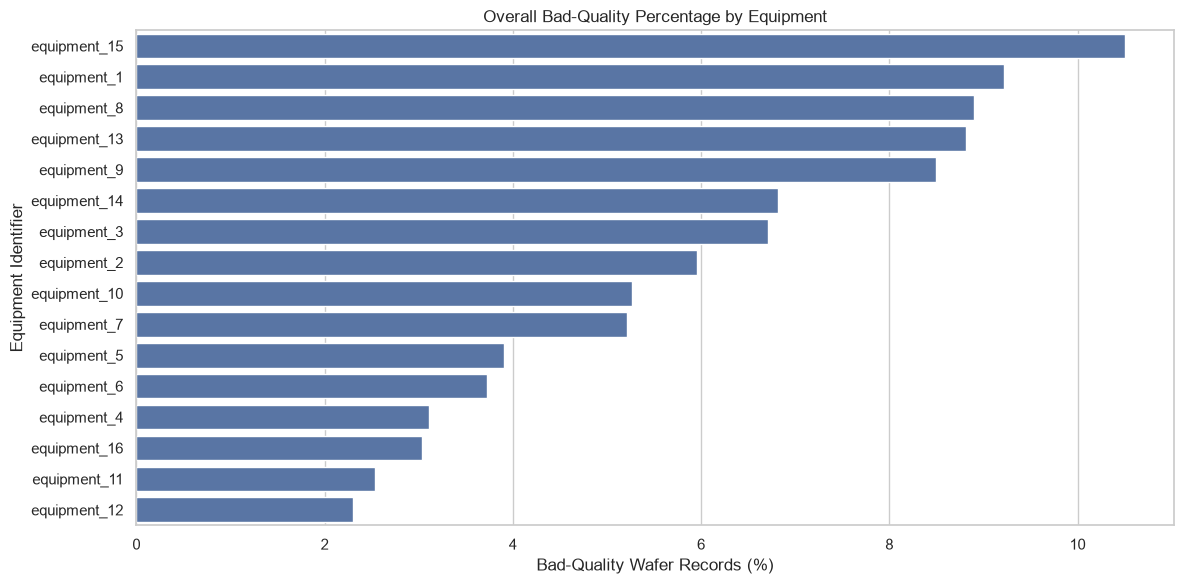

In [13]:

# Equipment quality comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    x=equipment_quality["overall_bad_pct"].values,
    y=equipment_quality.index
)

plt.title("Overall Bad-Quality Percentage by Equipment")
plt.xlabel("Bad-Quality Wafer Records (%)")
plt.ylabel("Equipment Identifier")

plt.tight_layout()
plt.show()

## 8. Limitations of Thickness-Only Quality Monitoring

Quantify the number of overall-bad wafer records
that nevertheless satisfy the thickness-quality label.

Examine whether these records have resistance,
resistivity, or combined electrical-property failures.

This analysis uses existing quality labels and
does not represent ML classification performance.

In [14]:

# STEP 2.5.10 - Thickness-only monitoring limitation

overall_bad = analysis_df["quality_overall"] == 1

thickness_good = analysis_df["quality_thickness"] == "good"

missed_by_thickness = (
    overall_bad & thickness_good
)

total_overall_bad = int(overall_bad.sum())

missed_count = int(missed_by_thickness.sum())

missed_percentage = (
    missed_count / total_overall_bad * 100
)

print("Overall-bad wafers:", total_overall_bad)

print(
    "Overall-bad wafers with good thickness:",
    missed_count
)

print(
    f"Percentage missed by thickness-only checks: "
    f"{missed_percentage:.2f}%"
)

print("\nElectrical failure combinations among these wafers:")

display(
    analysis_df.loc[
        missed_by_thickness,
        "failure_combination"
    ].value_counts().to_frame("Wafer Count")
)

Overall-bad wafers: 335
Overall-bad wafers with good thickness: 323
Percentage missed by thickness-only checks: 96.42%

Electrical failure combinations among these wafers:


,Wafer Count
failure_combination,
Resistivity,268
Resistance,29
Resistance + Resistivity,26



## 9. Key Findings and Interpretation

### Within-Wafer Variation

- Calculated range, standard deviation, and coefficient
  of variation for thickness, sheet resistance, and
  derived resistivity using 17 indexed measurements.
- Investigated how variation differs across wafers.
- Treated uniformity metrics as descriptive indicators,
  not industrial acceptance specifications.

### Measurement-Point Profiles

- Examined average material-property profiles across
  17 indexed measurement positions.
- Studied dataset-wide variability at each index.
- Did not invent undisclosed spatial wafer coordinates.
- Recognised that thickness and resistance measurement
  locations are nearby but not identical.

### Multi-Parameter Quality Assessment

- Analysed combinations of thickness, resistance,
  and resistivity quality failures.
- Investigated overlap between individual quality labels.
- Verified consistency with the overall quality indicator.
- Confirmed that 323 of 335 overall-bad wafers have
  a good thickness-quality classification (96.42%).

### Uniformity and Quality

- Compared within-wafer CV distributions between
  good and bad property-quality groups.
- Recognised that quality labels depend on the dataset's
  undisclosed measurement acceptance limits.
- Avoided interpreting CV as an official quality criterion.

### Equipment-Level Quality

- Compared overall quality outcomes across
  equipment identifiers.
- Examined sample counts and quality-label percentages.
- Did not attribute observed differences to confirmed
  equipment malfunctions.

### Implications for STRATUM

1. Implement virtual metrology for mean film thickness.
2. Evaluate sheet-resistance prediction as a second task.
3. Include measured wafer uniformity analysis.
4. Analyse physical and electrical quality jointly.
5. Provide equipment-level quality monitoring.
6. Automate detection and reporting of quality concerns.
7. Clearly distinguish predictions from measured results.

### Limitations

- Industrial acceptance thresholds are undisclosed.
- Exact wafer measurement coordinates are unavailable.
- Resistivity is derived rather than independently measured.
- The public data may not represent all factory production.
- Statistical association does not establish root cause.
- No ML model has yet been trained in this notebook.

### Conclusion

Multi-parameter semiconductor quality monitoring provides
a more complete assessment of recorded material properties
than thickness-only checks.

These results support STRATUM's proposed integration of
virtual metrology, measured quality monitoring, and
automated engineering analysis.

## 10. Wafer-Level Mean Consistency

Compare recorded wafer-level mean thickness and sheet
resistance with the arithmetic means of the corresponding
17-point measurements.

Differences are examined without modifying the dataset.

In [16]:

# Compare stored wafer-level means with 17-point means

mean_checks = [
    (
        "Thickness",
        "mean_thickness",
        "thickness_mean_17pt"
    ),
    (
        "Sheet Resistance",
        "mean_resistance",
        "resistance_mean_17pt"
    )
]

for property_name, recorded_col, calculated_col in mean_checks:

    absolute_difference = (
        analysis_df[recorded_col]
        - analysis_df[calculated_col]
    ).abs()

    print(f"\n{property_name} consistency:")

    print(
        "Mean absolute difference:",
        absolute_difference.mean()
    )

    print(
        "Maximum absolute difference:",
        absolute_difference.max()
    )

    display(
        absolute_difference.describe().round(10)
    )


Thickness consistency:
Mean absolute difference: 2.1785611375993242e-14
Maximum absolute difference: 1.1368683772161603e-13


count    5208.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64


Sheet Resistance consistency:
Mean absolute difference: 2.6008611147382108e-17
Maximum absolute difference: 7.676151381197371e-17


count    5208.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64


### Quantitative Findings

1. Mean within-wafer thickness CV: 2.4410%.
2. Mean within-wafer sheet resistance CV: 2.6694%.
3. Mean within-wafer derived resistivity CV: 0.3807%.
4. Total overall-bad wafers: 335.
5. Resistivity-only failures: 268.
6. Resistance-only failures: 29.
7. Combined resistance and resistivity failures: 26.
8. Overall-bad wafers with good thickness quality: 323 (96.42%).

### Engineering Interpretation

Within-wafer measurements reveal systematic indexed
patterns and variation that are not fully represented
by wafer-level averages.

Electrical-property quality indicators identify many
records that satisfy the thickness-quality criterion.

These findings justify a multi-parameter monitoring
approach in which thickness, resistance, resistivity,
uniformity, equipment behaviour, and quality indicators
are examined together.

The observed quality outcomes are based on post-process
measurements and do not establish the predictive
performance of STRATUM's future machine-learning models.